# Orthogonality of the batch effect and cross-batch linking

For each dataset we ask two questions in a shared PCA space:

1. **How much of the batch vector lies in the leading data directions?**
   (`f_k` = cumulative fraction of the batch vector's squared norm captured by
   the top-k *within-batch* PCs, compared against a random-direction null.)
2. **Do cross-batch linkers connect the correct cell types?** We compare MNN,
   OT-based, and shared-kNN links, relate the batch shift to the biological
   between-type distances, and scale the batch effect on one dataset (lupus) to
   see where each linker breaks down.

To add a dataset, append one dict to `DATASETS`.

In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import beta
from scipy.spatial.distance import pdist
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
import ot

# ---- global config ----
DATA_ROOT = "/home/sdamrich/CIN/submissions/ne_aligned/data_sharing"
N_PCS = 50            # PCA dimensionality; every dataset is analysed in this space
SUBSAMPLE = 1000      # cells per batch for the link comparison; set None to use all
OT_EPS_TIMES = 10     # OT Sinkhorn reg = median(cost) / OT_EPS_TIMES (reg 0.1, median-normalized)
K_NN = 15             # neighbors for the MNN and shared-kNN linkers
SEED = 0

In [2]:
def compute_ot_plan(x0, x1, eps_times=OT_EPS_TIMES, tol=1e-12, max_iter=10000):
    """Entropic OT plan on a median-normalized squared-Euclidean cost.

    Mirrors ne_aligned_utils.utils.compute_ot_plan, inlined because that module
    needs Python >= 3.11 while this kernel is 3.10. The Sinkhorn regularization
    is median(cost) / eps_times, i.e. reg=0.1 on a median-normalized cost when
    eps_times=10.
    """
    dist = ot.dist(x0, x1)                       # squared Euclidean
    reg = np.median(dist) / eps_times
    a = np.full(len(x0), 1.0 / len(x0))
    b = np.full(len(x1), 1.0 / len(x1))
    return ot.sinkhorn(a, b, dist, reg=reg, numItermax=max_iter, stopThr=tol)

In [3]:
# Dataset registry. Two shapes:
#   pca_meta   : one PCA matrix + metadata CSV; batch is a metadata column.
#   expr_split : X1.npy / X2.npy expression per batch + integer labels1/2.npy;
#                joint PCA is computed and cached as pca50.npy, batch = file origin.
DATASETS = [
    {
        "name": "yao_10x_ent_l2l3",
        "kind": "pca_meta",
        "pca": os.path.join(DATA_ROOT, "yao_10x_ent_l2l3", "ent_l2l3_pca50.npy"),
        "meta": os.path.join(DATA_ROOT, "yao_10x_ent_l2l3", "ent_l2l3_meta.csv"),
        "batch": ("donor_sex_label", "M", "F"),
        "labels": ["subclass_label", "cluster_label"],
    },
    {
        "name": "nCoV",
        "kind": "expr_split",
        "res_path": os.path.join(DATA_ROOT, "nCoV"),
        "labels": ["cell_type"],
    },
    {
        "name": "human_brain",
        "kind": "expr_split",
        "res_path": os.path.join(DATA_ROOT, "human_brain"),
        "labels": ["cell_type"],
    },
    {
        "name": "lupus",
        "kind": "expr_split",
        "res_path": os.path.join(DATA_ROOT, "lupus"),
        "labels": ["cell_type"],
    },
]

In [4]:
def load_dataset(cfg):
    """Load one dataset into a common (X, batch, labels) form.

    Returns
    -------
    X : (n, N_PCS) float array
        Joint PCA coordinates of both batches (read for pca_meta datasets,
        computed + cached as pca50.npy for expr_split datasets).
    batch : (n,) int array of 0/1.
    labels : dict[str, (n,) str array]
        One labelling per configured column; the first is the primary one.
    """
    if cfg["kind"] == "pca_meta":
        X = np.load(cfg["pca"])
        meta = pd.read_csv(cfg["meta"])
        col, va, vb = cfg["batch"]
        sel = meta[col].isin([va, vb]).values
        X, meta = X[sel], meta[sel].reset_index(drop=True)
        batch = (meta[col].values == vb).astype(int)
        labels = {c: meta[c].astype(str).values for c in cfg["labels"]}
        return X, batch, labels

    if cfg["kind"] == "expr_split":
        rp = cfg["res_path"]
        X1 = np.load(os.path.join(rp, "X1.npy"))
        X2 = np.load(os.path.join(rp, "X2.npy"))
        batch = np.r_[np.zeros(len(X1), int), np.ones(len(X2), int)]
        pca_path = os.path.join(rp, f"pca{N_PCS}.npy")
        if os.path.exists(pca_path):
            X = np.load(pca_path)
        else:
            X = PCA(n_components=N_PCS, random_state=SEED).fit_transform(
                np.concatenate([X1, X2]))
            np.save(pca_path, X)
        # integer codes are consistent across batches; their identity is all the
        # correctness/severity/chance computations need (cell_type_names.npy holds
        # the human-readable strings but is unused here and version-sensitive).
        l1 = np.load(os.path.join(rp, "labels1.npy"))
        l2 = np.load(os.path.join(rp, "labels2.npy"))
        lab = np.r_[l1, l2].astype(str)
        return X, batch, {cfg["labels"][0]: lab}

    raise ValueError(cfg["kind"])

In [5]:
def within_batch_fk(X, batch):
    """Cumulative fraction of the batch vector's squared norm in the top-k within-batch PCs.

    Each batch is centered separately and the pooled centered data is PCA'd, so
    the directions describe within-batch (biological) variation with the batch
    mean-shift removed. The batch vector b = mean(batch1) - mean(batch0) is
    projected onto that basis; f_k is the cumulative squared-projection fraction.
    """
    X0, X1 = X[batch == 0], X[batch == 1]
    b = X1.mean(0) - X0.mean(0)
    Xw = np.concatenate([X0 - X0.mean(0), X1 - X1.mean(0)])
    #Vw = PCA(n_components=X.shape[1]).fit(Xw).components_
    Vw = PCA(n_components=X.shape[1]).fit(X0).components_

    a = Vw @ b
    return np.cumsum(a**2) / (a**2).sum()


def beta_null_band(D, lo=0.025, hi=0.975):
    """Pointwise 95% band for f_k under a random direction: f_k ~ Beta(k/2, (D-k)/2)."""
    ks = np.arange(1, D)
    return ks, beta.ppf(lo, ks / 2, (D - ks) / 2), beta.ppf(hi, ks / 2, (D - ks) / 2)


def fk_to_angle(f):
    """Angle (degrees) between the batch vector and a subspace, from its captured fraction f_k.

    theta_k = arccos(sqrt(f_k)): 0 deg = vector lies in the subspace, 90 deg = orthogonal.
    """
    return np.degrees(np.arccos(np.sqrt(np.clip(f, 0.0, 1.0))))


def subsample(n, size, rng):
    """Indices of a random size-`size` subsample of `n` items (all of them if size is None)."""
    if size is None or size >= n:
        return np.arange(n)
    return rng.choice(n, size, replace=False)

In [6]:
def _directed_knn(Xq, Xref, k):
    """For each row of Xq, the indices of its k nearest neighbors in Xref."""
    return NearestNeighbors(n_neighbors=k).fit(Xref).kneighbors(Xq, return_distance=False)


def links_mnn_and_shared(X0, X1, k):
    """Cross-batch links from the two directed kNN searches.

    Returns (mnn, shared), each an (m, 2) int array of (i, j) pairs indexing X0
    and X1. `mnn` keeps pairs mutual in both directions (intersection);
    `shared` keeps pairs present in at least one direction (union).
    """
    nn01 = _directed_knn(X0, X1, k)                       # X0 -> X1
    nn10 = _directed_knn(X1, X0, k)                       # X1 -> X0
    e01 = {(int(i), int(j)) for i, row in enumerate(nn01) for j in row}
    e10 = {(int(i), int(j)) for j, row in enumerate(nn10) for i in row}
    inter = e01 & e10
    mnn = np.array(sorted(inter)) if inter else np.empty((0, 2), int)
    shared = np.array(sorted(e01 | e10))
    return mnn, shared


def links_ot(X0, X1):
    """Cross-batch links from the OT plan: each cell paired with its argmax-mass partner.

    Uses both the X0->X1 and X1->X0 argmax, unioned, to mirror the shared-kNN style.
    """
    P = compute_ot_plan(X0, X1)
    a01 = P.argmax(1)                                     # partner in X1 per X0 cell
    a10 = P.argmax(0)                                     # partner in X0 per X1 cell
    pairs = np.r_[np.c_[np.arange(len(X0)), a01],
                  np.c_[a10, np.arange(len(X1))]]
    return np.unique(pairs, axis=0)

In [7]:
def link_correctness(pairs, lab0, lab1):
    """Fraction of cross-batch links whose endpoints share a cell-type label."""
    if len(pairs) == 0:
        return np.nan
    return (lab0[pairs[:, 0]] == lab1[pairs[:, 1]]).mean()


def chance_same(lab0, lab1):
    """Same-label fraction expected under random pairing: sum_c p0_c * p1_c."""
    cats = np.unique(np.concatenate([lab0, lab1]))
    p0 = np.array([(lab0 == c).mean() for c in cats])
    p1 = np.array([(lab1 == c).mean() for c in cats])
    return float((p0 * p1).sum())


def interclass_distances(X, batch, lab):
    """Pairwise distances between cell-type centroids, free of the batch shift.

    Each batch is mean-centered before pooling, so the between-type geometry
    reflects biological differences rather than the batch mean-shift. Returns the
    condensed vector of inter-centroid distances (one per unordered type pair).
    """
    Xc = X.astype(np.float64, copy=True)
    for bb in (0, 1):
        Xc[batch == bb] -= Xc[batch == bb].mean(0)
    cent = np.array([Xc[lab == c].mean(0) for c in np.unique(lab)])
    return pdist(cent)


def batch_interclass_ratio(X, batch, lab):
    """Batch-shift magnitude relative to biological between-type distances.

    Returns (ratio_nearest, ratio_median): the batch vector norm ||b||, with
    b = mean(batch1) - mean(batch0), divided by the nearest and the median
    inter-type-centroid distance. A ratio near or above 1 means the batch shift
    is as large as the biological gap it is compared against, so a linker taking
    nearest cross-batch cells can be pushed into the wrong type.
    """
    b = X[batch == 1].mean(0) - X[batch == 0].mean(0)
    d = interclass_distances(X, batch, lab)
    nb = float(np.linalg.norm(b))
    return nb / float(d.min()), nb / float(np.median(d))


def lupus_batch_sweep(res_path, scales, n_pcs=N_PCS, sub=SUBSAMPLE, seed=SEED):
    """Rescale the lupus batch shift and track geometry + link quality.

    The natural batch shift b = mean(X2) - mean(X1) in gene-expression space is
    rescaled to `scale * b` (scale=1 is the natural data, 3 the tripled-effect
    experiment, 0 aligns the batch means). For each scale the pooled expression is
    re-PCA'd to n_pcs and we record the batch/inter-type distance ratios and the
    same-cell-type fraction of each linker. The batch indices for the O(n^2)
    linkers are subsampled once and reused across scales, so only the shift size
    changes, not the cells compared.
    """
    X1 = np.load(os.path.join(res_path, "X1.npy"))
    X2 = np.load(os.path.join(res_path, "X2.npy"))
    lab = np.r_[np.load(os.path.join(res_path, "labels1.npy")),
                np.load(os.path.join(res_path, "labels2.npy"))].astype(str)
    batch = np.r_[np.zeros(len(X1), int), np.ones(len(X2), int)]
    b = X2.mean(0) - X1.mean(0)

    rng = np.random.default_rng(seed)
    i0, i1 = np.where(batch == 0)[0], np.where(batch == 1)[0]
    s0 = i0[subsample(len(i0), sub, rng)]
    s1 = i1[subsample(len(i1), sub, rng)]

    rows = []
    for s in scales:
        X2s = X2 + (s - 1.0) * b                           # batch mean separation -> s*b
        Xp = PCA(n_components=n_pcs, random_state=seed).fit_transform(
            np.concatenate([X1, X2s]))
        rn, rm = batch_interclass_ratio(Xp, batch, lab)
        X0p, X1p = Xp[s0], Xp[s1]
        lab0, lab1 = lab[s0], lab[s1]
        mnn, shared = links_mnn_and_shared(X0p, X1p, K_NN)
        pairs = {"MNN": mnn, "OT": links_ot(X0p, X1p), "shared-kNN": shared}
        rows.append(dict(
            scale=float(s), ratio_nearest=rn, ratio_median=rm,
            corr={m: link_correctness(p, lab0, lab1) for m, p in pairs.items()}))
    chance = chance_same(lab[s0], lab[s1])
    return rows, chance


def gini(x):
    """Gini coefficient of a nonnegative vector (0 = all equal, higher = concentrated)."""
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    if n == 0 or x.sum() == 0:
        return np.nan
    return float((2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum()))


def coverage_by_type(pairs, lab0, lab1):
    """How evenly a linker spreads its cross-batch links over the cell types.

    Each cell's degree is the number of cross-batch links it takes part in. A
    type's relative coverage is the mean degree of its cells divided by the mean
    degree over all cells (pooled over both batches): ~1 means the type is linked
    at the average per-cell rate, near 0 means it is barely linked (missed), >1
    over-linked. Using per-cell degree rather than total links per type makes the
    measure independent of how many cells a type has, the fair way to compare
    types of very different abundance. Also returns the Gini coefficient of the
    per-cell degree distribution (0 = every cell linked equally, higher = a few
    cells take most links). Arrays are sorted by abundance (descending).
    """
    n0, n1 = len(lab0), len(lab1)
    deg = (np.r_[np.bincount(pairs[:, 0], minlength=n0),
                 np.bincount(pairs[:, 1], minlength=n1)]
           if len(pairs) else np.zeros(n0 + n1))
    lab = np.concatenate([lab0, lab1])
    md = deg.mean()
    types = np.unique(lab)
    rel = np.array([deg[lab == c].mean() / md if md else np.nan for c in types])
    ncell = np.array([int((lab == c).sum()) for c in types])
    order = np.argsort(-ncell)
    return dict(types=types[order], rel=rel[order], ncell=ncell[order], gini=gini(deg))


## Run the analysis over all datasets

In [8]:
rng = np.random.default_rng(SEED)
LINKERS = ["MNN", "OT", "shared-kNN"]
results = {}

for cfg in DATASETS:
    name = cfg["name"]
    X, batch, labels = load_dataset(cfg)
    primary = cfg["labels"][0]

    frac_cum = within_batch_fk(X, batch)                  # f_k on the full data
    rn, rm = batch_interclass_ratio(X, batch, labels[primary])  # batch size vs. types

    # subsample each batch for the (O(n^2)) link comparison
    i0, i1 = np.where(batch == 0)[0], np.where(batch == 1)[0]
    s0 = i0[subsample(len(i0), SUBSAMPLE, rng)]
    s1 = i1[subsample(len(i1), SUBSAMPLE, rng)]
    X0, X1 = X[s0], X[s1]
    lab0, lab1 = labels[primary][s0], labels[primary][s1]

    mnn, shared = links_mnn_and_shared(X0, X1, K_NN)
    pair_sets = {"MNN": mnn, "OT": links_ot(X0, X1), "shared-kNN": shared}

    results[name] = dict(
        frac_cum=frac_cum,
        corr={m: link_correctness(p, lab0, lab1) for m, p in pair_sets.items()},
        cov={m: coverage_by_type(p, lab0, lab1) for m, p in pair_sets.items()},
        ratio_nearest=rn, ratio_median=rm,
        chance=chance_same(lab0, lab1),
        n_links={m: len(p) for m, p in pair_sets.items()},
    )
    r = results[name]
    print(f"{name:18s} " + "  ".join(
        f"{m}={r['corr'][m]:.1%}(n={r['n_links'][m]})" for m in LINKERS)
        + f"  chance={r['chance']:.1%}")

yao_10x_ent_l2l3   MNN=95.0%(n=5692)  OT=93.0%(n=1667)  shared-kNN=93.4%(n=24308)  chance=34.2%


nCoV               MNN=60.2%(n=5632)  OT=51.9%(n=1581)  shared-kNN=50.0%(n=24368)  chance=11.8%


human_brain        MNN=98.9%(n=6351)  OT=95.0%(n=1766)  shared-kNN=97.3%(n=23649)  chance=19.4%


lupus              MNN=80.8%(n=3091)  OT=79.3%(n=1745)  shared-kNN=63.7%(n=26909)  chance=16.2%


## Figure 1: batch vector vs. the leading data directions

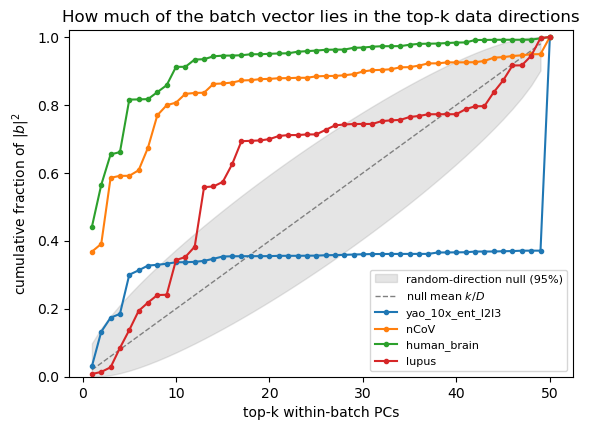

In [9]:
D = N_PCS
ks, lo, hi = beta_null_band(D)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.fill_between(ks, lo, hi, color="gray", alpha=0.2, label="random-direction null (95%)")
ax.plot(ks, ks / D, color="gray", ls="--", lw=1, label=r"null mean $k/D$")
for name, r in results.items():
    ax.plot(np.arange(1, D + 1), r["frac_cum"], "-o", ms=3, label=name)
ax.set(xlabel="top-k within-batch PCs",
       ylabel=r"cumulative fraction of $\|b\|^2$", ylim=(0, 1.02),
       title="How much of the batch vector lies in the top-k data directions")
ax.legend(fontsize=8)
fig.savefig(os.path.join(DATA_ROOT, "norm_fraction.png"), dpi=200)

## Figure 1b: angle between the batch vector and the top-k PC subspace

The same information as Figure 1, expressed as an angle
`theta_k = arccos(sqrt(f_k))`. Near 0 deg means the batch vector lies inside
the top-k data directions; near 90 deg means it is orthogonal to them. A
dataset dropping *below* the null band is more aligned with the leading data
directions than a random direction would be.

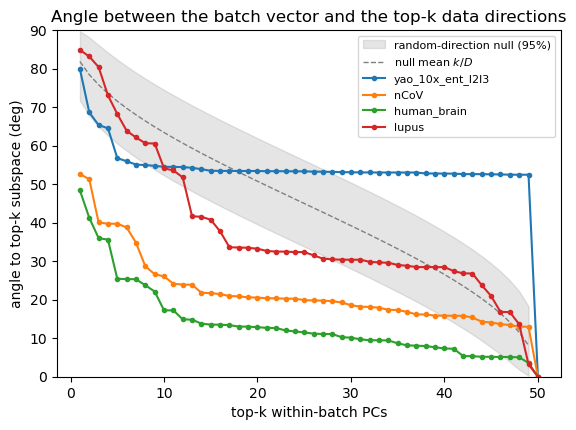

In [10]:
D = N_PCS
ks, lo, hi = beta_null_band(D)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
# null band mapped through the (decreasing) angle transform: hi f_k -> low angle
ax.fill_between(ks, fk_to_angle(hi), fk_to_angle(lo), color="gray", alpha=0.2,
                label="random-direction null (95%)")
ax.plot(ks, fk_to_angle(ks / D), color="gray", ls="--", lw=1, label=r"null mean $k/D$")
for name, r in results.items():
    ax.plot(np.arange(1, D + 1), fk_to_angle(r["frac_cum"]), "-o", ms=3, label=name)
ax.set(xlabel="top-k within-batch PCs", ylabel="angle to top-k subspace (deg)",
       ylim=(0, 90), title="Angle between the batch vector and the top-k data directions")
ax.legend(fontsize=8)
fig.savefig(os.path.join(DATA_ROOT, "angle.png"), dpi=200)

## Figure 2: link correctness by linker

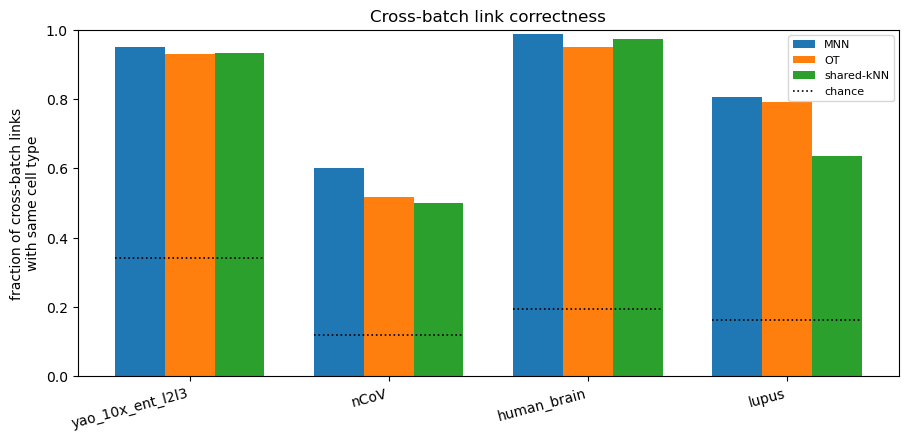

In [11]:
names = list(results)
x = np.arange(len(names))
w = 0.25
fig, ax = plt.subplots(figsize=(1.9 * len(names) + 3, 4.5))
for t, m in enumerate(LINKERS):
    ax.bar(x + (t - 1) * w, [results[n]["corr"][m] for n in names], w, label=m)
for xi, n in zip(x, names):                               # per-group chance reference
    ax.hlines(results[n]["chance"], xi - 1.5 * w, xi + 1.5 * w, color="k", ls=":", lw=1.2)
handles, _ = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color="k", ls=":", lw=1.2, label="chance"))
ax.set(xticks=x, ylim=(0, 1),
       ylabel="fraction of cross-batch links\nwith same cell type",
       title="Cross-batch link correctness")
ax.set_xticklabels(names, rotation=15, ha="right")
ax.legend(handles=handles, fontsize=8)
fig.savefig(os.path.join(DATA_ROOT, "cross_batch_correctness.png"), dpi=200)

## Figure 3: batch shift vs. biological between-type distances

The size of the batch vector `b = mean(batch1) - mean(batch0)` relative to the
distances between cell-type centroids (measured on batch-centered data, so the
shift itself does not inflate them). A ratio near or above 1 means the batch
mean-shift is as large as the biological gap between types, so a linker that
just takes nearest cross-batch cells can be pushed into the wrong type.

yao_10x_ent_l2l3   ||b||/nearest=0.41  ||b||/median=0.38
nCoV               ||b||/nearest=1.94  ||b||/median=0.42
human_brain        ||b||/nearest=0.16  ||b||/median=0.07
lupus              ||b||/nearest=2.44  ||b||/median=0.78


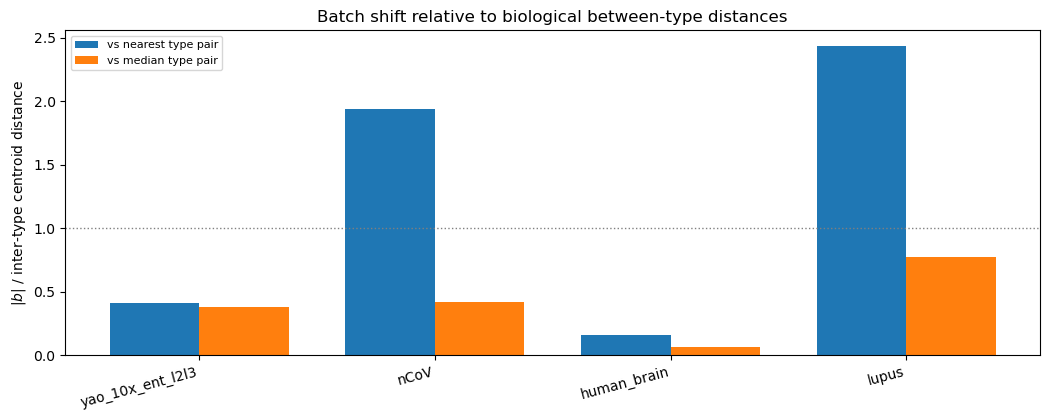

In [12]:
names = list(results)
x = np.arange(len(names))
w = 0.38
fig, ax = plt.subplots(figsize=(1.9 * len(names) + 3, 4.3))
ax.bar(x - w / 2, [results[n]["ratio_nearest"] for n in names], w, label="vs nearest type pair")
ax.bar(x + w / 2, [results[n]["ratio_median"] for n in names], w, label="vs median type pair")
ax.axhline(1.0, color="gray", ls=":", lw=1)
ax.set(xticks=x, ylabel=r"$\|b\|$ / inter-type centroid distance",
       title="Batch shift relative to biological between-type distances")
ax.set_xticklabels(names, rotation=15, ha="right")
ax.legend(fontsize=8)
fig.tight_layout()
for n in names:
    print(f"{n:18s} ||b||/nearest={results[n]['ratio_nearest']:.2f}  "
          f"||b||/median={results[n]['ratio_median']:.2f}")

## Figure 4: scaling the batch effect (lupus)

Starting from the lupus data, the batch shift is rescaled from 0 (batch means
aligned) to 4x its natural size; `scale=1` is the natural data and `scale=3`
reproduces the tripled-effect case (dashed guides). The left panel shows the
shift growing relative to the biological between-type distances; the right panel
shows how each linker's correctness responds. OT keeps its median-normalized
regularization, so its cost rescales with the shift and it stays robust, while
the nearest-neighbor linkers (MNN, shared-kNN) degrade once the shift rivals the
between-type gaps.

In [13]:
scales = np.arange(0.0, 10.01, 0.5)
sweep, sweep_chance = lupus_batch_sweep(os.path.join(DATA_ROOT, "lupus"), scales)
sc = [r["scale"] for r in sweep]


scale=0.0  ratio_near=0.00  MNN=81.6%  OT=75.0%  shared-kNN=72.8%
scale=0.5  ratio_near=1.22  MNN=79.4%  OT=75.8%  shared-kNN=69.1%
scale=1.0  ratio_near=2.44  MNN=77.9%  OT=77.0%  shared-kNN=58.4%
scale=1.5  ratio_near=3.66  MNN=75.2%  OT=78.1%  shared-kNN=46.6%
scale=2.0  ratio_near=4.88  MNN=70.1%  OT=78.6%  shared-kNN=38.9%
scale=2.5  ratio_near=6.09  MNN=65.2%  OT=78.0%  shared-kNN=33.0%
scale=3.0  ratio_near=7.31  MNN=58.0%  OT=77.3%  shared-kNN=28.8%
scale=3.5  ratio_near=8.53  MNN=51.1%  OT=76.6%  shared-kNN=25.8%
scale=4.0  ratio_near=9.75  MNN=39.7%  OT=77.1%  shared-kNN=23.4%
scale=4.5  ratio_near=10.97  MNN=30.7%  OT=76.8%  shared-kNN=21.2%
scale=5.0  ratio_near=12.19  MNN=22.3%  OT=76.7%  shared-kNN=19.4%
scale=5.5  ratio_near=13.41  MNN=19.4%  OT=76.1%  shared-kNN=17.9%
scale=6.0  ratio_near=14.63  MNN=15.3%  OT=75.9%  shared-kNN=16.7%
scale=6.5  ratio_near=15.85  MNN=12.7%  OT=76.1%  shared-kNN=15.7%
scale=7.0  ratio_near=17.06  MNN=10.1%  OT=76.2%  shared-kNN=15.0%
scal

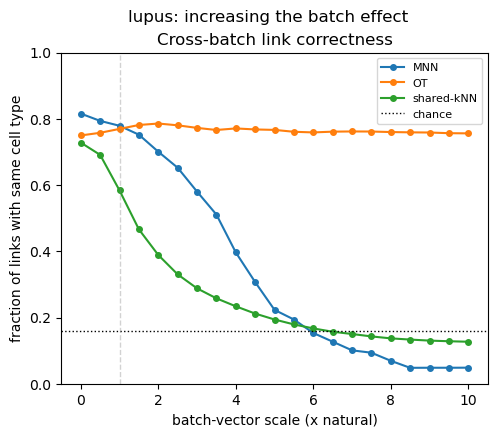

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(5.5, 4.3))
for m in LINKERS:
    ax.plot(sc, [r["corr"][m] for r in sweep], "-o", ms=4, label=m)
ax.axhline(sweep_chance, color="k", ls=":", lw=1, label="chance")
ax.set(xlabel="batch-vector scale (x natural)",
        ylabel="fraction of links with same cell type", ylim=(0, 1),
        title="Cross-batch link correctness")
ax.legend(fontsize=8)

ax.axvline(1.0, color="gray", alpha=0.35, lw=1, ls="--")
fig.suptitle("lupus: increasing the batch effect")
fig.savefig(os.path.join(DATA_ROOT, "link_correctness_by_batch_effect_strength.png"), dpi=200)

for r in sweep:
    print(f"scale={r['scale']:.1f}  ratio_near={r['ratio_nearest']:.2f}  "
          + "  ".join(f"{m}={r['corr'][m]:.1%}" for m in LINKERS))

scale=0.0  ratio_near=0.00  MNN=81.6%  OT=75.0%  shared-kNN=72.8%
scale=0.5  ratio_near=1.22  MNN=79.4%  OT=75.8%  shared-kNN=69.1%
scale=1.0  ratio_near=2.44  MNN=77.9%  OT=77.0%  shared-kNN=58.4%
scale=1.5  ratio_near=3.66  MNN=75.2%  OT=78.1%  shared-kNN=46.6%
scale=2.0  ratio_near=4.88  MNN=70.1%  OT=78.6%  shared-kNN=38.9%
scale=2.5  ratio_near=6.09  MNN=65.2%  OT=78.0%  shared-kNN=33.0%
scale=3.0  ratio_near=7.31  MNN=58.0%  OT=77.3%  shared-kNN=28.8%
scale=3.5  ratio_near=8.53  MNN=51.1%  OT=76.6%  shared-kNN=25.8%
scale=4.0  ratio_near=9.75  MNN=39.7%  OT=77.1%  shared-kNN=23.4%
scale=4.5  ratio_near=10.97  MNN=30.7%  OT=76.8%  shared-kNN=21.2%
scale=5.0  ratio_near=12.19  MNN=22.3%  OT=76.7%  shared-kNN=19.4%
scale=5.5  ratio_near=13.41  MNN=19.4%  OT=76.1%  shared-kNN=17.9%
scale=6.0  ratio_near=14.63  MNN=15.3%  OT=75.9%  shared-kNN=16.7%
scale=6.5  ratio_near=15.85  MNN=12.7%  OT=76.1%  shared-kNN=15.7%
scale=7.0  ratio_near=17.06  MNN=10.1%  OT=76.2%  shared-kNN=15.0%
scal

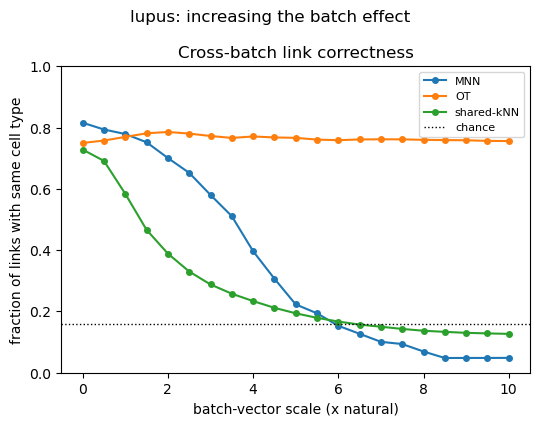

In [15]:

fig, ax = plt.subplots(1, 1, figsize=(5.5, 4.3))
for m in LINKERS:
    ax.plot(sc, [r["corr"][m] for r in sweep], "-o", ms=4, label=m)
ax.axhline(sweep_chance, color="k", ls=":", lw=1, label="chance")
ax.set(xlabel="batch-vector scale (x natural)",
        ylabel="fraction of links with same cell type", ylim=(0, 1),
        title="Cross-batch link correctness")
ax.legend(fontsize=8)

fig.suptitle("lupus: increasing the batch effect")
fig.tight_layout()

for r in sweep:
    print(f"scale={r['scale']:.1f}  ratio_near={r['ratio_nearest']:.2f}  "
          + "  ".join(f"{m}={r['corr'][m]:.1%}" for m in LINKERS))

## Figure 5: cell-type coverage by linker

Do the linkers connect every cell type across batches, or only a convenient few?
For each cell we count its cross-batch links (its degree) and, per type, take the
mean degree of that type's cells divided by the overall mean degree. This
**relative coverage** is ~1 when a type is linked at the average per-cell rate,
near 0 when a type is barely linked (missed), and >1 when it is over-linked.
Working with per-cell degree (not total links per type) makes coverage
independent of type abundance, so a type is not called well-covered just because
it is large. `G` is the Gini coefficient of the per-cell degree distribution
(0 = every cell linked equally, higher = a few cells absorb most of the links).

Where the types are fine-grained or rare (nCoV, lupus), MNN leaves several types
under-linked (relative coverage toward 0) while OT keeps every type near 1
(uniform coverage, a consequence of its marginal constraints). shared-kNN sits in
between: every cell keeps at least its k neighbors so no type collapses to 0, but
the per-cell degree, and hence the Gini, is more uneven than OT.

KeyError: 'cov'

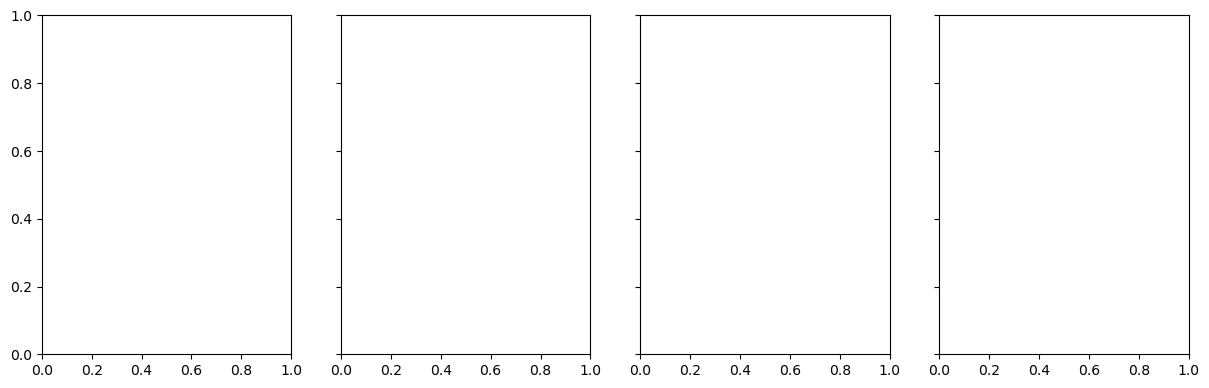

In [373]:
fig, axes = plt.subplots(1, len(results), figsize=(3.7 * len(results), 4.4), sharey=True)
axes = np.atleast_1d(axes)
palette = plt.rcParams["axes.prop_cycle"].by_key()["color"]
jit = np.random.default_rng(SEED)
for ax, name in zip(axes, results):
    cov = results[name]["cov"]
    for t, m in enumerate(LINKERS):
        d = cov[m]
        xj = t + (jit.random(len(d["rel"])) - 0.5) * 0.32
        ax.scatter(xj, d["rel"], s=15 + 170 * d["ncell"] / d["ncell"].max(),
                   color=palette[t], alpha=0.6, edgecolors="k", linewidths=0.4, zorder=3)
        ax.text(t, 0.97, f"G={d['gini']:.2f}", ha="center", va="top", fontsize=7,
                transform=ax.get_xaxis_transform())
    ax.axhline(1.0, color="gray", ls=":", lw=1)
    ax.set_xticks(range(len(LINKERS)))
    ax.set_xticklabels(LINKERS, rotation=20)
    ax.set_title(name, fontsize=9)
    ax.set_ylim(bottom=-0.05)
axes[0].set_ylabel("relative coverage\n(type mean degree / overall mean degree)")
fig.suptitle("Cell-type coverage: point = type (size prop. to #cells), dotted = uniform, G = Gini of per-cell degree")
fig.tight_layout()

for name in results:
    print(name)
    for m in LINKERS:
        d = results[name]["cov"][m]
        j = int(np.argmin(d["rel"]))
        print(f"  {m:11s} Gini={d['gini']:.2f}  min rel-cov={d['rel'][j]:.2f} "
              f"({d['types'][j]}, n={d['ncell'][j]})  median={np.nanmedian(d['rel']):.2f}  "
              f"#types<0.5={(d['rel'] < 0.5).sum()}/{len(d['rel'])}")

## Appendix: do the two batches share PCA structure?

Sanity check for the within-batch-PCA premise, on a single dataset. Small
principal angles mean the two batches' leading subspaces largely agree.

In [ ]:
from scipy.linalg import subspace_angles

cfg = DATASETS[0]                                          # yao_10x_ent_l2l3
X, batch, _ = load_dataset(cfg)
k = 10
V0 = PCA(n_components=k).fit(X[batch == 0]).components_.T
V1 = PCA(n_components=k).fit(X[batch == 1]).components_.T
ang = np.degrees(subspace_angles(V0, V1))
print(f"{cfg['name']}: principal angles (deg) between the two batches' top-{k} PCA subspaces")
print(np.round(ang, 1))

yao_10x_ent_l2l3: principal angles (deg) between the two batches' top-10 PCA subspaces
[63.3 25.  12.4  8.9  7.3  6.7  5.2  4.1  3.3  2.6]
